In [24]:
import pandas as pd

df = pd.read_csv("data.csv", encoding="ISO-8859-1")
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [25]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate rows: 5268


In [26]:
df = df.dropna(subset=["CustomerID"])
print(len(df))

406829


In [27]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.startswith("C")]
print(len(df))

397924


In [28]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print(len(df))

397884


In [29]:
df = df.drop_duplicates()
print(len(df))

392692


In [30]:
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")

In [31]:
df["InvoiceMonth"] = df["InvoiceDate"].dt.strftime("%Y-%m")
df["Revenue"] = (df["Quantity"] * df["UnitPrice"]).round(2)
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceMonth,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,2010-12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,2010-12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12,20.34


In [32]:
print(df.shape)
print("Customers:", df["CustomerID"].nunique())
print("Orders:", df["InvoiceNo"].nunique())
print("Total revenue:", round(df["Revenue"].sum()))
print(df["InvoiceDate"].min(), df["InvoiceDate"].max())

(392692, 10)
Customers: 4338
Orders: 18532
Total revenue: 8887209
2010-12-01 08:26:00 2011-12-09 12:50:00


In [33]:
df.to_csv("Ecom_Clean.csv", index=False)

In [34]:
df = df[~df["InvoiceNo"].isin(["541431", "581483"])]
print(df.shape)

(392690, 10)


In [35]:
import sqlite3

con = sqlite3.connect(":memory:")
df.to_sql("sales", con, index=False, if_exists="replace")

392690

In [36]:
pd.read_sql("""
SELECT InvoiceMonth,
       ROUND(SUM(Revenue)) AS revenue,
       COUNT(DISTINCT InvoiceNo) AS orders,
       COUNT(DISTINCT CustomerID) AS customers
FROM sales
GROUP BY InvoiceMonth
ORDER BY InvoiceMonth
""", con)

,InvoiceMonth,revenue,orders,customers
0,2010-12,570423.0,1400,885
1,2011-01,490918.0,986,740
2,2011-02,446085.0,997,758
3,2011-03,594082.0,1321,974
4,2011-04,468374.0,1149,856
5,2011-05,677355.0,1555,1056
6,2011-06,660046.0,1393,991
7,2011-07,598963.0,1331,949
8,2011-08,644051.0,1280,935
9,2011-09,950690.0,1755,1266


In [37]:
pd.read_sql("""
SELECT Country,
       ROUND(SUM(Revenue)) AS revenue,
       ROUND(100.0 * SUM(Revenue) / (SELECT SUM(Revenue) FROM sales), 1) AS pct_of_total
FROM sales
GROUP BY Country
ORDER BY revenue DESC
LIMIT 5
""", con)

,Country,revenue,pct_of_total
0,United Kingdom,7039371.0,81.5
1,Netherlands,285446.0,3.3
2,EIRE,265262.0,3.1
3,Germany,228678.0,2.6
4,France,208934.0,2.4


In [38]:
pd.read_sql("""
SELECT Description,
       SUM(Quantity) AS units,
       ROUND(SUM(Revenue)) AS revenue
FROM sales
GROUP BY Description
ORDER BY revenue DESC
LIMIT 5
""", con)

,Description,units,revenue
0,REGENCY CAKESTAND 3 TIER,12374,142265.0
1,WHITE HANGING HEART T-LIGHT HOLDER,36706,100392.0
2,JUMBO BAG RED RETROSPOT,46078,85041.0
3,POSTAGE,3120,77804.0
4,PARTY BUNTING,15279,68785.0


In [39]:
pd.read_sql("""
WITH orders_per_customer AS (
    SELECT CustomerID, COUNT(DISTINCT InvoiceNo) AS orders
    FROM sales
    GROUP BY CustomerID
)
SELECT CASE WHEN orders = 1 THEN 'One-time' ELSE 'Repeat' END AS customer_type,
       COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_customers
FROM orders_per_customer
GROUP BY customer_type
""", con)

,customer_type,customers,pct_customers
0,One-time,1493,34.4
1,Repeat,2844,65.6


In [40]:
pd.read_sql("""
WITH orders_per_customer AS (
    SELECT CustomerID, COUNT(DISTINCT InvoiceNo) AS orders
    FROM sales
    GROUP BY CustomerID
)
SELECT CASE WHEN o.orders = 1 THEN 'One-time' ELSE 'Repeat' END AS customer_type,
       ROUND(SUM(s.Revenue)) AS revenue,
       ROUND(100.0 * SUM(s.Revenue) / SUM(SUM(s.Revenue)) OVER (), 1) AS pct_revenue
FROM sales s
JOIN orders_per_customer o ON s.CustomerID = o.CustomerID
GROUP BY customer_type
""", con)

,customer_type,revenue,pct_revenue
0,One-time,536809.0,6.2
1,Repeat,8104747.0,93.8


In [41]:
cohort = pd.read_sql("""
WITH first_purchase AS (
    SELECT CustomerID, MIN(InvoiceMonth) AS cohort_month
    FROM sales
    WHERE InvoiceMonth <= '2011-11'
    GROUP BY CustomerID
),
activity AS (
    SELECT DISTINCT s.CustomerID, f.cohort_month, s.InvoiceMonth AS active_month
    FROM sales s
    JOIN first_purchase f ON s.CustomerID = f.CustomerID
    WHERE s.InvoiceMonth <= '2011-11'
)
SELECT cohort_month,
       (CAST(SUBSTR(active_month, 1, 4) AS INT) - CAST(SUBSTR(cohort_month, 1, 4) AS INT)) * 12
       + (CAST(SUBSTR(active_month, 6, 2) AS INT) - CAST(SUBSTR(cohort_month, 6, 2) AS INT)) AS month_number,
       COUNT(DISTINCT CustomerID) AS customers
FROM activity
GROUP BY cohort_month, month_number
ORDER BY cohort_month, month_number
""", con)
cohort.head(8)

,cohort_month,month_number,customers
0,2010-12,0,885
1,2010-12,1,324
2,2010-12,2,286
3,2010-12,3,340
4,2010-12,4,321
5,2010-12,5,352
6,2010-12,6,321
7,2010-12,7,309


In [42]:
counts = cohort.pivot(index="cohort_month", columns="month_number", values="customers")
retention = (counts.divide(counts[0], axis=0) * 100).round(1)
retention.iloc[:, :7]

month_number,0,1,2,3,4,5,6
cohort_month,,,,,,,
2010-12,100.0,36.6,32.3,38.4,36.3,39.8,36.3
2011-01,100.0,22.1,26.7,23.1,32.2,28.8,24.8
2011-02,100.0,18.7,18.7,28.4,27.1,24.7,25.3
2011-03,100.0,15.0,25.2,19.9,22.3,16.8,26.8
2011-04,100.0,21.3,20.3,21.0,19.7,22.7,21.7
2011-05,100.0,19.0,17.3,17.3,20.8,23.2,26.4
2011-06,100.0,17.4,15.7,26.4,23.1,33.5,NaN
2011-07,100.0,18.1,20.7,22.3,27.1,NaN,NaN
2011-08,100.0,20.7,24.9,24.3,NaN,NaN,NaN


In [43]:
import matplotlib.pyplot as plt

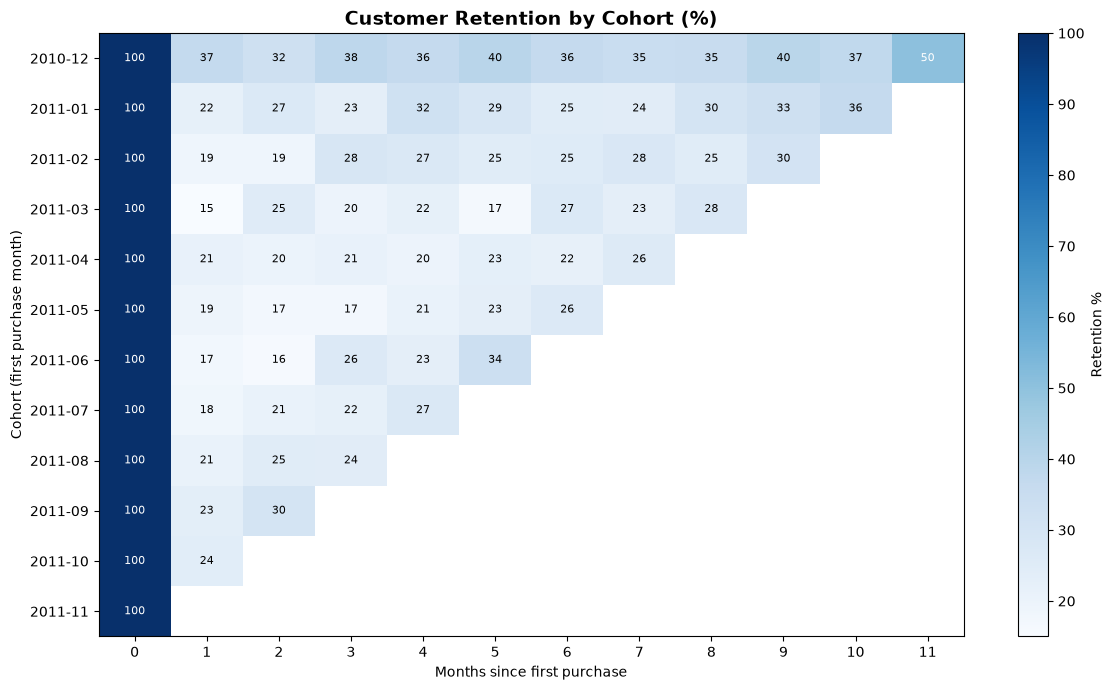

In [44]:
plt.figure(figsize=(12, 7))
plt.imshow(retention, cmap="Blues", aspect="auto")
plt.colorbar(label="Retention %")
plt.xticks(range(retention.shape[1]), retention.columns)
plt.yticks(range(retention.shape[0]), retention.index)
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.iloc[i, j]
        if pd.notna(v):
            plt.text(j, i, f"{v:.0f}", ha="center", va="center",
                     color="white" if v > 50 else "black", fontsize=8)
plt.title("Customer Retention by Cohort (%)", fontsize=14, fontweight="bold")
plt.xlabel("Months since first purchase")
plt.ylabel("Cohort (first purchase month)")
plt.tight_layout()
plt.savefig("chart_cohort.png", dpi=150)
plt.show()

In [45]:
retention.mean().round(1).loc[[1, 3, 6]]

month_number
1    21.5
3    24.6
6    26.9
dtype: float64

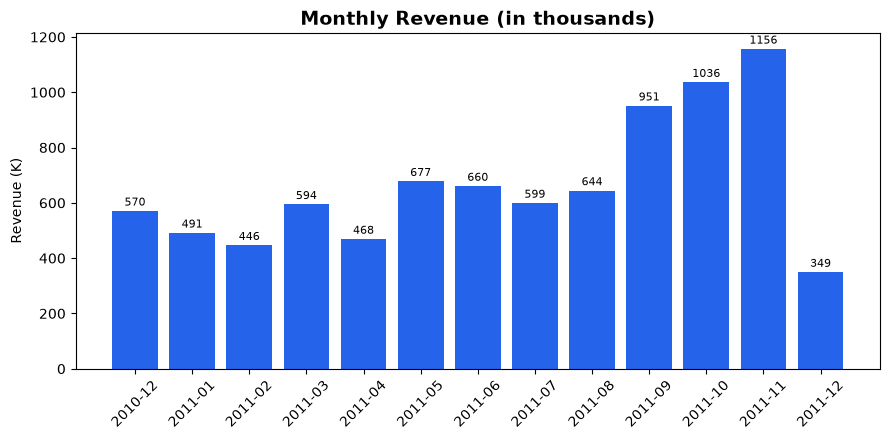

In [46]:
m = df.groupby("InvoiceMonth")["Revenue"].sum() / 1000
plt.figure(figsize=(9, 4.5))
bars = plt.bar(m.index, m.values, color="#2563EB")
plt.title("Monthly Revenue (in thousands)", fontsize=14, fontweight="bold")
plt.ylabel("Revenue (K)")
plt.xticks(rotation=45)
plt.bar_label(bars, fmt="%.0f", padding=2, fontsize=8)
plt.tight_layout()
plt.savefig("chart_monthly_revenue.png", dpi=150)
plt.show()